Missing values:
 CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


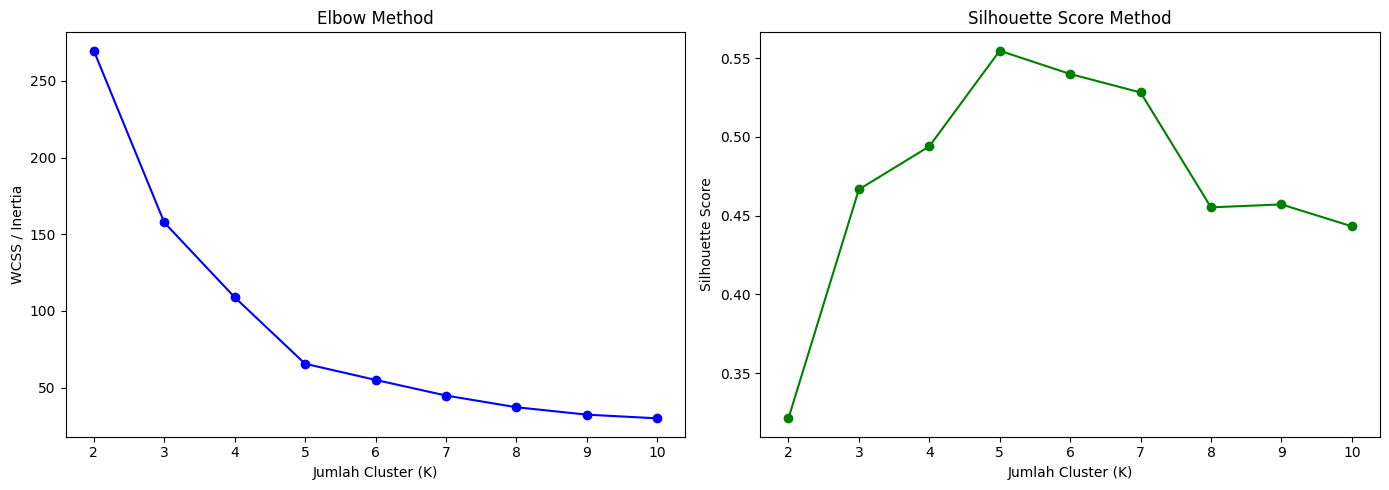

Hasil Evaluasi Model (K=5):
- Silhouette Score : 0.5547 (Mendekati 1 = Cluster terpisah dengan baik)
- Davies-Bouldin   : 0.5722 (Mendekati 0 = Cluster lebih kompak)


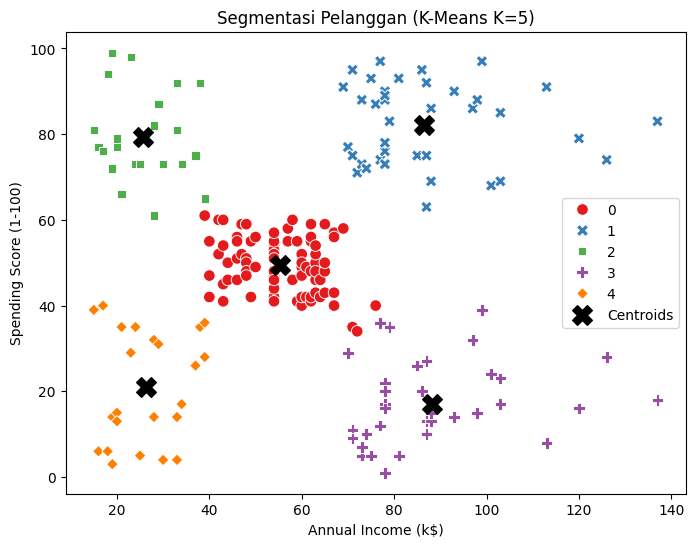

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. PEMBERSIHAN DATA & PREPROCESSING
# Load dataset
url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"
df = pd.read_csv(url)

# Cek missing values dan informasi data
print("Missing values:\n", df.isnull().sum())

# Pilih fitur yang relevan untuk clustering
X = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()

# Scaling fitur (sangat penting untuk algoritma berbasis jarak seperti K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# 2. EVALUASI UNTUK MENENTUKAN K OPTIMAL (BEFORE TRAINING)
wcss = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Visualisasi Elbow Method & Silhouette Score
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(k_range, wcss, marker="o", color="b")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("Jumlah Cluster (K)")
ax[0].set_ylabel("WCSS / Inertia")

ax[1].plot(k_range, silhouette_scores, marker="o", color="g")
ax[1].set_title("Silhouette Score Method")
ax[1].set_xlabel("Jumlah Cluster (K)")
ax[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()


# 3. TRAINING MODEL
# Berdasarkan grafik Elbow & Silhouette, misal K terbaik = 5
optimal_k = 5
model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = model.fit_predict(X_scaled)

# Tambahkan label cluster ke dataframe asli
df["Cluster"] = cluster_labels


# 4. EVALUASI HASIL CLUSTERING
sil_avg = silhouette_score(X_scaled, cluster_labels)
db_index = davies_bouldin_score(X_scaled, cluster_labels)

print(f"Hasil Evaluasi Model (K={optimal_k}):")
print(f"- Silhouette Score : {sil_avg:.4f} (Mendekati 1 = Cluster terpisah dengan baik)")
print(f"- Davies-Bouldin   : {db_index:.4f} (Mendekati 0 = Cluster lebih kompak)")


# 5. VISUALISASI HASIL CLUSTERING
plt.figure(figsize=(8, 6))

# Plot data points berdasarkan cluster
sns.scatterplot(
    x=X["Annual Income (k$)"],
    y=X["Spending Score (1-100)"],
    hue=cluster_labels,
    palette="Set1",
    s=70,
    style=cluster_labels,
)

# Plot titik pusat cluster (Centroids) - kembalikan skala ke data asli
centroids_original = scaler.inverse_transform(model.cluster_centers_)
plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    s=200,
    c="black",
    marker="X",
    label="Centroids",
)

plt.title(f"Segmentasi Pelanggan (K-Means K={optimal_k})")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()